# Exploring the Measure 110 data

Run the cells top to bottom (Shift+Enter). Use the **measure_110** kernel.
Make sure you've run `python build_db.py` at least once so the database exists.

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt

# Open the database built by build_db.py (read-only so it never gets locked).
con = duckdb.connect("db/measure110.duckdb", read_only=True)

## Overdose death rates per 100,000
The final result table. `rate_low`/`rate_high` widen only where months were suppressed.

In [2]:
rates = con.execute("SELECT * FROM mart_overdose_rate ORDER BY drug, year").df()
rates

,year,drug,deaths_est,suppressed_months,population,rate_per_100k,rate_low,rate_high
0,2018,cocaine,60.0,12.0,4190713,1.4,0.3,2.6
1,2019,cocaine,66.0,11.0,4217737,1.6,0.5,2.6
2,2020,cocaine,68.0,9.0,4241507,1.6,0.8,2.5
3,2021,cocaine,79.0,9.0,4246155,1.9,1.0,2.7
4,2022,cocaine,107.0,5.0,4240137,2.5,2.1,3.0
5,2023,cocaine,149.0,4.0,4233358,3.5,3.1,3.9
6,2024,cocaine,149.0,2.0,4272371,3.5,3.3,3.7
7,2018,heroin,140.0,4.0,4190713,3.3,3.0,3.7
8,2019,heroin,146.0,2.0,4217737,3.5,3.3,3.7
9,2020,heroin,192.0,1.0,4241507,4.5,4.4,4.6


## Plot: opioid overdose death rates over time
All four opioid categories. Dashed line = Measure 110 (Feb 2021); dotted = HB 4002 recriminalization (Sept 2024).

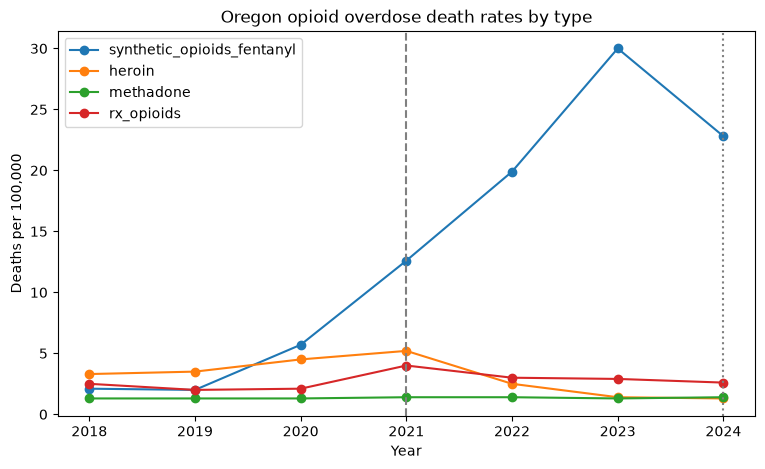

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
opioids = ["synthetic_opioids_fentanyl", "heroin", "methadone", "rx_opioids"]
for drug in opioids:
    d = rates[rates.drug == drug]
    ax.plot(d.year, d.rate_per_100k, marker="o", label=drug)
ax.axvline(2021, ls="--", color="gray")          # Measure 110 effective Feb 2021
ax.axvline(2024, ls=":", color="gray")           # HB 4002 recriminalization Sept 2024
ax.set_xlabel("Year")
ax.set_ylabel("Deaths per 100,000")
ax.set_title("Oregon opioid overdose death rates by type")
ax.legend()
plt.show()

## Normalized: each drug indexed to its 2018 rate (= 1.0)
Strips out the size differences so you compare *relative* change. A value of 3.0
means "3x the 2018 rate." The flat line at 1.0 is the 2018 baseline.

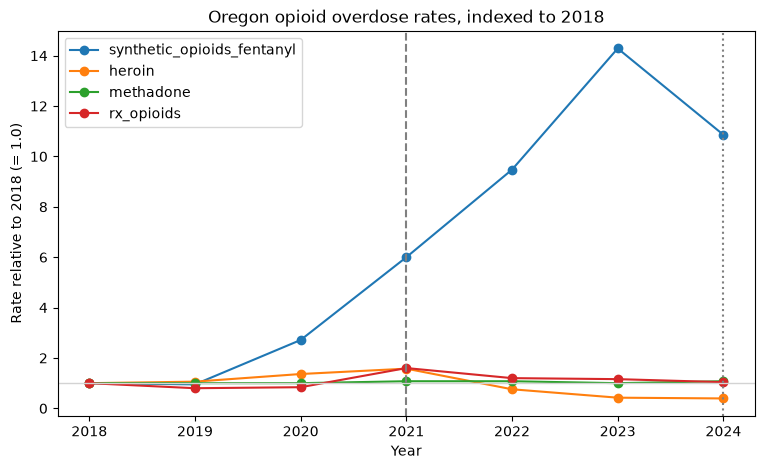

In [4]:
base_year = 2018
fig, ax = plt.subplots(figsize=(9, 5))
for drug in opioids:
    d = rates[rates.drug == drug].sort_values("year")
    base = d.loc[d.year == base_year, "rate_per_100k"].iloc[0]
    ax.plot(d.year, d.rate_per_100k / base, marker="o", label=drug)
ax.axhline(1.0, color="lightgray", lw=1)         # the 2018 baseline
ax.axvline(2021, ls="--", color="gray")          # Measure 110 effective Feb 2021
ax.axvline(2024, ls=":", color="gray")           # HB 4002 recriminalization Sept 2024
ax.set_xlabel("Year")
ax.set_ylabel(f"Rate relative to {base_year} (= 1.0)")
ax.set_title("Oregon opioid overdose rates, indexed to 2018")
ax.legend()
plt.show()

## Your turn: run any SQL
Edit the query below and re-run. (This one scans the big SDUD files, so it takes ~a minute.)

In [5]:
con.execute("""
    SELECT "Year" AS year, COUNT(*) AS oregon_records
    FROM raw_sdud
    WHERE "State" = 'OR'
    GROUP BY 1 ORDER BY 1
""").df()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,year,oregon_records
0,2018,88807
1,2019,90724
2,2020,92057
3,2021,91532
4,2022,95028
5,2023,98854
6,2024,99433
7,2025,96176
